# t-SNE, one iteration at a time

**300 MNIST test images · 30 per digit · seed 42**

Run the cells from top to bottom. The data is loaded from the local `mnist_test.csv.zip` file supplied in this folder; running it needs no internet download. Each image becomes one dot. Its pixels stay fixed while its two map coordinates move.

We will inspect images → compute fixed original affinities **P** → initialise coordinates **Y** → calculate map affinities **Q** → calculate one scalar **KL loss** → differentiate with respect to every coordinate → update all dots together → repeat.

This teaching implementation uses exact pairwise calculations and ordinary gradient descent with backtracking. We deliberately omit early exaggeration, momentum, and approximate neighbours so that every accepted update reduces the same ordinary KL objective. Production t-SNE commonly uses those additional techniques. This run is an explanation of the mechanics, and its layout may differ from library defaults.

**Interactive output:** the last cell contains an iteration slider and image hover viewer. Trust the notebook in Jupyter and run that cell to enable its JavaScript. Static plots also show saved checkpoints.

## 1. Inspect the real images

The file contains the official MNIST test split in CSV form. The first column is the digit label, and the remaining 784 columns are flattened 28 × 28 pixel values. We select 30 test rows from every digit using seed 42, giving 300 images.

Flatten 28 × 28 pixels into 784 features and divide by 255. We keep all 784 features and use Euclidean distances directly, so the relationship to the pixels remains visible.

[7 6 2 2 1 0 8 7 9 4]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
[7001 7576 2765 4456 3543 1651 6311 8931 9705  678]


[7 6 2 2 1 0 8 7 9 4]
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
[7001 7576 2765 4456 3543 1651 6311 8931 9705  678]


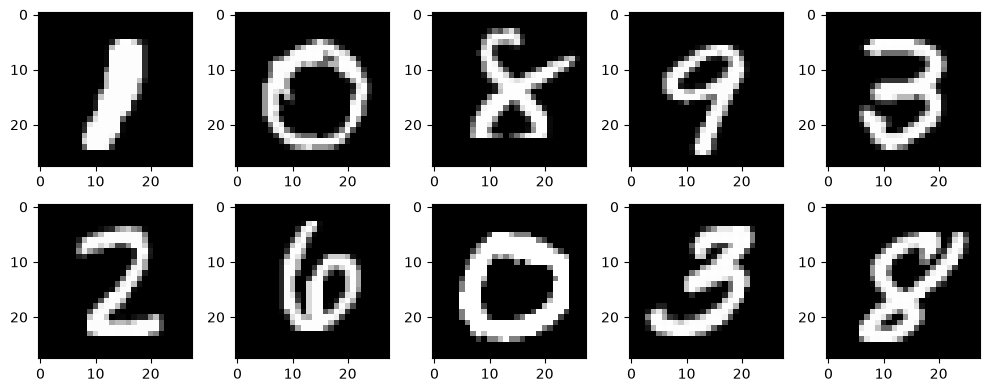

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

DATA_FILE = 'mnist_test.csv'

mnist_rows = pd.read_csv(DATA_FILE, header=None).to_numpy(dtype=np.uint8)

labels_full=mnist_rows[:,0]
pixels_full=mnist_rows[:,1:]


rng=np.random.default_rng(SEED)

def random_sample():
    inspect_list=[]
    inspect_list = rng.choice(
        len(labels_full),
        size=10,
        replace=False,
    )

    labels = labels_full[inspect_list]
    pixels = pixels_full[inspect_list]
    original_ids = inspect_list
    return labels,pixels,original_ids,

labels=random_sample()[0]
print(labels)
pixels=random_sample()[1]
print(pixels)
position = random_sample()[2]
print(position)

images = pixels.reshape(10, 28, 28)


def display_digits(position,images):
    fig, axes = plt.subplots(2,5,figsize=(10,4))

    for position, ax in enumerate(axes.flat):
        ax.imshow(images[position], cmap="grey", vmin=0,vmax=255)
        ax.axis("on")

    plt.tight_layout()
    plt.show()

display_digits(position,images)

Now selecting 300 images to work with.

In [4]:
def train_data():
    subset_indices = []
    for digit in range(10):
        matching_rows = np.where(labels_full == digit)[0]
        chosen_rows = rng.choice(
            matching_rows,
            size=30,
            replace=False
        )
        subset_indices.extend(chosen_rows) #not arary because that will create a nested list. extend adds each item separately.
    subset_indices = np.asarray(subset_indices)
    rng.shuffle(subset_indices)
    return subset_indices


labels = labels_full[train_data()]
pixels = pixels_full[train_data()]
X = pixels.astype(np.float64) / 255.0
N = len(X)
assert X.shape == (300, 784)

print(np.bincount(labels, minlength=10))

[30 30 30 30 30 30 30 30 30 30]


## 2. Compare original pixel vectors

`squared_distances[i, j]` is the sum of the squared pixel differences between two images. A low distance means their pixel patterns are similar. We exclude an image itself when inspecting its neighbours.

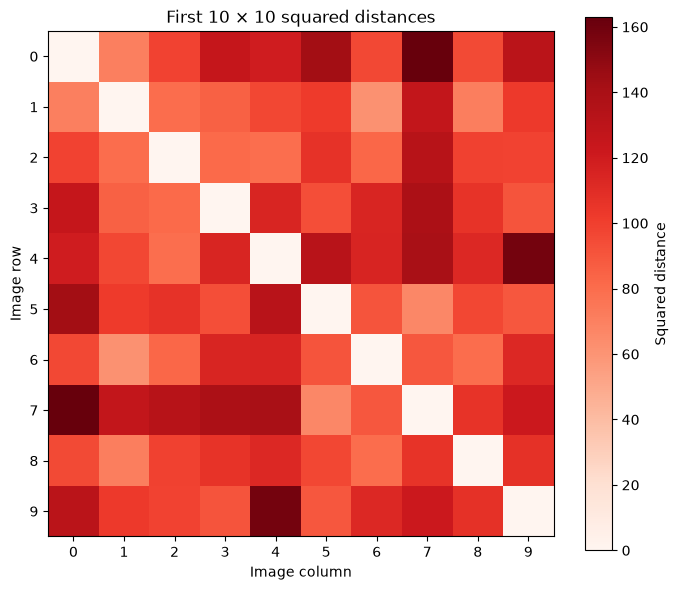

Distance matrix shape: (300, 300)


In [5]:
def pairwise_squared_distances(values):
    """
    Find the squared difference for every pair of 784-pixel images.
    Return a count-by-count matrix of pairwise squared distances.
    """
    count = len(values)
    distances = np.zeros((count, count))

    for i in range(count):
        for j in range(count):
            squared_difference = 0
            for pixel in range(values.shape[1]):
                difference = values[i, pixel] - values[j, pixel]
                squared_difference += difference ** 2
            distances[i, j] = squared_difference

    return distances


squared_distances = pairwise_squared_distances(X)


def show_first_distance_heatmap(distances, size=10):
    """Show the first size-by-size image distances as a heatmap."""
    block = distances[:size, :size]

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(block, cmap="Reds", vmin=0)
    ax.set_xlabel("Image column")
    ax.set_ylabel("Image row")
    ax.set_title(f"First {size} × {size} squared distances")
    fig.colorbar(image, ax=ax, label="Squared distance")

    ax.set_xticks(range(size))
    ax.set_yticks(range(size))

    plt.tight_layout()
    plt.show()


show_first_distance_heatmap(squared_distances)
print("Distance matrix shape:", squared_distances.shape)

## 3. Build P once, before any dots move

For image i, Gaussian weights become conditional probabilities:

$$p_{j|i}=\frac{\exp(-d_{ij}^2/(2\sigma_i^2))}{\sum_{k\ne i}\exp(-d_{ik}^2/(2\sigma_i^2))}.$$

We search for each image's Gaussian width so its conditional distribution has the chosen perplexity. With natural logs, entropy is $H_i=-\sum_j p_{j|i}\log p_{j|i}$ and perplexity is $\exp(H_i)$.

Then symmetrise using $p_{ij}=(p_{j|i}+p_{i|j})/(2N)$. Every conditional row sums to one; the **whole joint P matrix** sums to one. P remains fixed throughout all embedding iterations.

In [ ]:
PERPLEXITY = 20.0
ENTROPY_DIFFERENCE_THRESHOLD = 1e-8

def map_affinities_highd(distances, perplexity, entropy_difference_threshold):
    count = len(distances)

    conditional = np.zeros_like(distances)
    sigmas = np.zeros(count)
    achieved = np.zeros(count)

    target_entropy = np.log(perplexity)

    for i in range(count):
            neighbours = np.arange(count) != i
            row = distances[i, neighbours]

            beta = 1.0
            lower_beta = 0.0
            upper_beta = np.inf
            for x in range(100): #100 just max iteration
                weights=np.exp(-beta*(row-row.min())) #remove the minimum to ensure the closest neighbour has weight at 1.
                probabilities = weights/weights.sum() #normalise to find probability of each beta for every pair (related to variance)
                positive = probabilities>0 #only consider those with probability over 0 to remove NaN or -inf values (np.log(0.0) → -inf)
                entropy= -np.sum(probabilities[positive]*np.log(probabilities[positive])) #finding entropy 
                difference = entropy-target_entropy #find how different the entropy is to the given perplexity

                if abs(difference) < entropy_difference_threshold:
                    break

                # bisection method
                if difference > 0: #beta is inversely proportional to variance so if entropy is too high (too spread out) increase beta to reduce variance to make gaussian kernal narrower
                    lower_beta = beta
                    if np.isinf(upper_beta):
                        beta = 2 * beta
                    else:
                        beta = (beta + upper_beta) / 2
                else:
                    upper_beta = beta
                    beta = (lower_beta + beta) / 2

            if abs(difference) >= 1e-6:
                raise RuntimeError(
                    f"Perplexity search did not converge for row {i}."
                )

    conditional[i, neighbours] = probabilities
    sigmas[i] = np.sqrt(1.0 / (2.0 * beta))
    achieved[i] = np.exp(entropy)

    P = (conditional + conditional.T) / (2 * count)

    return P, conditional, sigmas, achieved


map_affinities_highd(squared_distances, PERPLEXITY, ENTROPY_DIFFERENCE_THRESHOLD)

(array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 4.80495432e-06],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 3.47149955e-06],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 1.37596259e-06],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 7.63540780e-07],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 5.18343904e-07],
        [4.80495432e-06, 3.47149955e-06, 1.37596259e-06, ...,
         7.63540780e-07, 5.18343904e-07, 0.00000000e+00]], shape=(300, 300)),
 array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
         0.        ],
        [0.        , 0.        , 0.        , ..., 0.   

## 4. Put every image at an initial 2D position

Y has shape N × 2. Column 0 is horizontal and column 1 is vertical. We choose seeded random starting positions with standard deviation 0.01 for this ordinary gradient-descent demonstration. Image labels have no role in choosing or updating these coordinates.

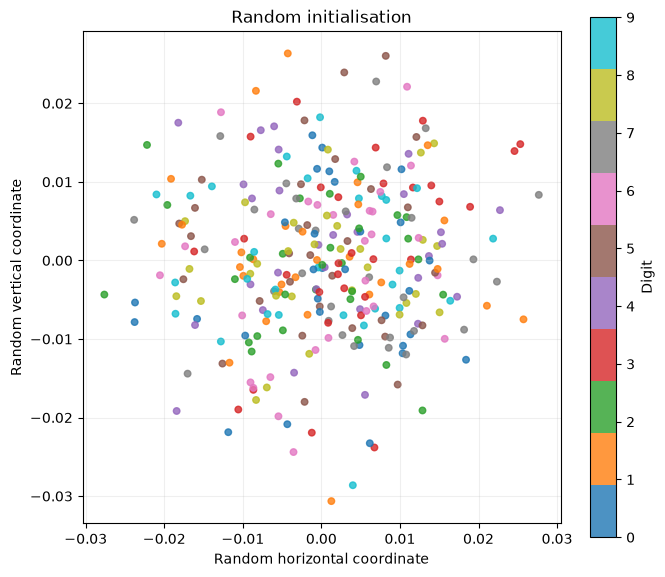

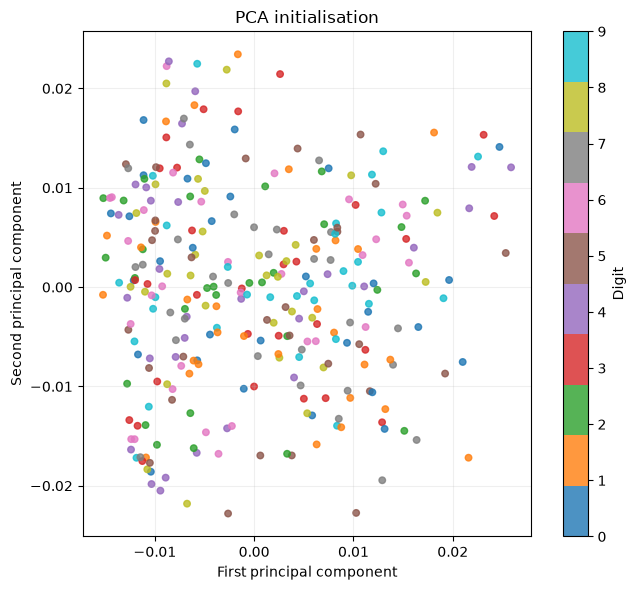

In [ ]:
def random_initialise(N):
    '''
    Random initialisation of 2D embedding map
    '''
    Y = rng.normal(0.0, 0.01, size=(N, 2))
    return Y


def pca_initialise(values=None):
    '''
    PCA initialisation of 2D embedding map 
    '''

    centered = values - values.mean(axis=0)
    U, singular_values, components = np.linalg.svd(centered, full_matrices=False)

    Y = centered @ components[:2].T

    # Match the random initialisation scale and remove component magnitude differences.
    Y = Y / Y.std(axis=0, keepdims=True) * 0.01

    #Choose a sign to make largest value direction positive.
    for dimension in range(2):
        largest = np.argmax(np.abs(Y[:, dimension]))
        if Y[largest, dimension] < 0:
            Y[:, dimension] *= -1

    return Y


def plot_random_initialisation(N):
    '''
    Plot the random starting coordinates, coloured by digit label.
    '''
    Y = random_initialise(N)

    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels[:N], cmap="tab10",
                         vmin=0, vmax=9, s=22, alpha=0.8)

    ax.set_xlabel("Random horizontal coordinate")
    ax.set_ylabel("Random vertical coordinate")
    ax.set_title("Random initialisation")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
    plt.tight_layout()
    plt.show()


def plot_pca_initialisation(values=None):
    '''Plot the PCA starting coordinates, coloured by digit label.'''
    if values is None:
        values = X

    Y = pca_initialise(values)

    fig, ax = plt.subplots(figsize=(7, 6))
    scatter = ax.scatter(Y[:, 0], Y[:, 1], c=labels[:len(Y)], cmap="tab10",
                         vmin=0, vmax=9, s=22, alpha=0.8)

    ax.set_xlabel("First principal component")
    ax.set_ylabel("Second principal component")
    ax.set_title("PCA initialisation")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
    plt.tight_layout()
    plt.show()

plot_random_initialisation(N)
plot_pca_initialisation(X)

## 5. Turn positions into Q, and calculate one scalar KL loss

$$w_{ij}=\frac{1}{1+\|y_i-y_j\|^2},\quad Z=\sum_{k\ne l}w_{kl},\quad q_{ij}=w_{ij}/Z.$$

$$L=\sum_{i\ne j}p_{ij}\log(p_{ij}/q_{ij}).$$

Both directions of each pair are included. Self-pairs are excluded. An individual term can be negative; the total KL is nonnegative. Moving one dot changes Z and therefore changes every normalised q, even for pairs whose endpoints stayed still.

In [ ]:
def map_affinities_2d(Y):
    '''
    Takes input of the current 2D coordinates of each dot and outputs a 300x300 matrix of 
    the affinities (probability-like similarity score between two points) of each dot using
    t-distribution (1/1+squared distance) 
    '''
    differences=np.zeros(len(Y),len(Y), 2) #come back and review this!!!
    for j in range(len(Y)):
        differences[i, j] = Y[i] - Y[j]
    squared_distances = np.sum(differences ** 2, axis=2)

    weights = 1.0 / (1.0 + squared_distances) #t-distribution to avoid crowding 
    np.fill_diagonal(weights, 0.0)

    Z = weights.sum()
    Q = weights / Z

    return Q, weights

map_affinities_2d(random_initialise(300))

## 6. Differentiate with respect to both coordinates of every dot

$$\nabla_{y_i} L=4\sum_{j\ne i}(p_{ij}-q_{ij})w_{ij}(y_i-y_j).$$

`gradient[i, 0]` is the derivative of the **total** loss with respect to dot i's horizontal coordinate. `gradient[i, 1]` is its vertical derivative. We compute all rows from the same current positions.

The implementation below is the same sum in matrix form. Multiplying each difference by its coefficient and summing gives `sum(coefficients) * y_i - sum(coefficients * y_j)`.

In [ ]:
def differente_coordinate():
    Q, weights = map_affinities(Y)
    gradient = np.zeros_like(Y)
    P = map_affinities_highd()[0]
    difference=np.zeros(len(Y))

    for i in range(len(Y)):
        for j in range(len(Y)):
            if i == j:
                continue

            difference = Y[i] - Y[j]  # [dx, dy]
            coefficient = 4 * (P[i, j] - Q[i, j]) * weights[i, j] 
            gradient[i] += coefficient * difference

    # Update all dots after computing every gradient from the same Y
    Y = Y - learning_rate * gradient

## 7. Verify the derivative numerically

Move just one coordinate a tiny amount in each direction. The slope estimated from the two losses should agree with the analytical gradient. This tests the normalisation and factor of four as well as the chain rule. We check a spread-out configuration to avoid tiny initial derivatives masking errors.

## 8. Take ONE simultaneous update

$$Y_{\mathrm{new}}=Y-\eta\nabla L(Y).$$

All coordinates move using gradients calculated at the old positions. The line search starts at the chosen step size and halves it if necessary until the ordinary KL loss decreases sufficiently. Trial steps are not accepted iterations. Recentring removes an irrelevant translation and preserves every pair distance.

## 9. HERE IS THE ITERATION LOOP

This cell restarts from iteration 0 every time you run it. Within each cycle, calculate Q → calculate the gradient → update every dot → record the new loss. P and the pixels remain fixed. The progress messages report accepted steps. We stop at the gradient tolerance or the iteration limit.

## 10. Inspect what changed

The loss belongs to the whole embedding. Each coordinate has its own derivative. The checkpoints below have independent axis limits to make the early configurations readable; use the coordinate ticks to compare scales. Colours show digit labels, which the optimiser never receives. A visible island alone does not establish a genuine population or a new digit class.

## 11. Scrub through iterations and hover over images

Move the slider to a saved iteration. Hover near a dot to see its actual MNIST image, label, subset row, and test-split row number. Turn off autoscaling to keep the same axes across frames. The saved frames are every ten iterations, plus the first update and final frame.

If the viewer is blank, trust the notebook and rerun this cell in Jupyter. The static outputs above remain available in viewers that block JavaScript.

## What to try next

1. Change `FOCUS` to inspect a different image and its strongest original neighbours.
2. Change `PERPLEXITY` to 5 or 40 and rerun from the P calculation onward, using the same initial coordinates. P changes, so KL values across these different objectives are not directly comparable as quality scores.
3. Change only the random seed and rerun the coordinate initialisation onward. P stays fixed, so the final KL objectives are comparable.

The direct implementation costs O(N²) time and memory for pairwise operations. Keep the external subset small while learning. Increasing the iteration limit may refine the layout, but small gradients do not guarantee a global optimum or faithful preservation of every neighbourhood.

## Sources

- [van der Maaten & Hinton, Visualizing Data using t-SNE (2008)](https://www.jmlr.org/papers/v9/vandermaaten08a.html). Affinity equations, KL objective, analytical gradient, and production optimisation choices.
- [MNIST test split CSV](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv). The attached `mnist_test.csv.zip` contains 10,000 test rows; this notebook selects a reproducible 300-row subset.
- [Wattenberg et al., How to Use t-SNE Effectively (2016)](https://distill.pub/2016/misread-tsne/). Interpretation of clusters and hyperparameters.